# Notebook 3: Treino, Modelação e Otimização de Hiperparâmetros

**Unidade Curricular:** Dados e Aprendizagem Automática (DAA) — 2026/2027

Neste notebook treinamos e avaliamos modelos para prever a faixa etária (`AGE_RANGE`), usando os dados finais do Notebook 2. A métrica é o **Macro F1**, a mesma da competição. O percurso é o seguinte:

1. Um **modelo de referência** simples (árvore de decisão);
2. A **comparação de vários classificadores** nas mesmas condições;
3. A **otimização** do melhor modelo (Gradient Boosting);
4. A **análise dos erros** do Gradient Boosting e a sua submissão;
5. O **XGBoost**, a combinação com um regressor e o **modelo ordinal**, que dão o modelo final (secção 7);
6. O **registo** de todas as submissões e experiências (secção 8).

## 1. Configuração e Carregamento dos Dados

Importamos as bibliotecas, carregamos os dados finais do Notebook 2 e definimos os elementos comuns a todo o notebook:

- a **validação cruzada estratificada em 5 partes** (sempre as mesmas partes, para que as comparações entre modelos sejam justas);
- a **faixa mínima** de cada pessoa (Notebook 2, secção 6), usada para corrigir previsões impossíveis;
- a função que gera o ficheiro de submissão no formato do Kaggle.

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, RandomizedSearchCV
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

warnings.filterwarnings('ignore', category=FutureWarning)
plt.style.use('ggplot')

DATA_DIR = '../data'
SUBMISSIONS_DIR = '../submissions'
TARGET = 'AGE_RANGE'
RANDOM_STATE = 42
AGE_LABELS = ['15-17', '18-19', '20-24', '25-29', '30-34', '35-39', '40-44', '45-49',
              '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80-84', '85+']

# Dados finais do Notebook 2
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train_nb02.csv'), index_col='PID')
test_df = pd.read_csv(os.path.join(DATA_DIR, 'test_nb02.csv'), index_col='PID')
X = train_df.drop(columns=TARGET)
y = train_df[TARGET]
X_test = test_df[X.columns]

# Faixa mínima de cada pessoa (para a correção das previsões)
faixa_min = X['FAIXA_MINIMA'].values
faixa_min_test = X_test['FAIXA_MINIMA'].values

# Validação cruzada (sempre as mesmas 5 partes)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def gerar_submissao(previsoes, nome):
    """Gera o CSV de submissão a partir do ficheiro de exemplo do Kaggle (RowId + AGE_RANGE)."""
    submissao = pd.read_csv(os.path.join(DATA_DIR, 'example_submission_10.csv'))
    assert len(submissao) == len(previsoes) == 3655, "O nº de linhas não coincide"
    submissao[TARGET] = previsoes
    caminho = os.path.join(SUBMISSIONS_DIR, nome)
    submissao.to_csv(caminho, index=False)
    print(f"Submissão guardada em {caminho}")


print(f"X: {X.shape} | y: {y.shape} | X_test: {X_test.shape}")

X: (10962, 339) | y: (10962,) | X_test: (3655, 339)


## 2. Modelo de Referência: Árvore de Decisão

Começamos por um modelo simples e interpretável, que serve de referência para os seguintes. Treinamos uma árvore de decisão com `class_weight='balanced'`, que dá mais peso às faixas etárias menos representadas (importante para o Macro F1), e testamos várias profundidades máximas: uma árvore demasiado curta não capta os padrões (*underfitting*), e uma demasiado profunda memoriza o treino (*overfitting*).

,max_depth,Macro F1,Desvio padrão
0,4,0.3090,0.0082
1,6,0.3806,0.0153
2,8,0.4044,0.0130
3,10,0.3996,0.0146
4,12,0.3910,0.0073
5,15,0.3780,0.0064
6,None,0.3697,0.0137


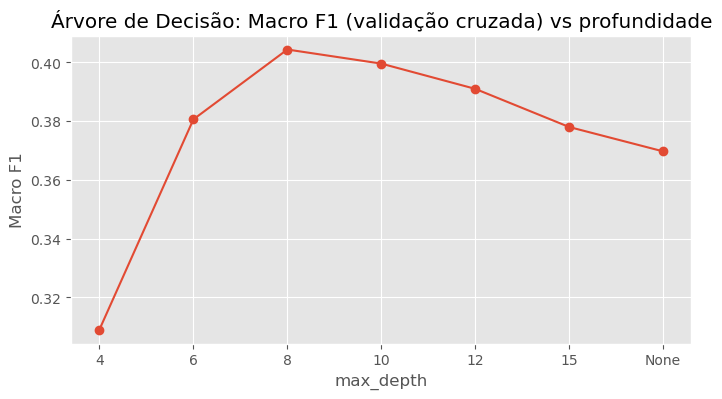

In [2]:
resultados = []
for profundidade in [4, 6, 8, 10, 12, 15, None]:
    arvore = DecisionTreeClassifier(max_depth=profundidade, class_weight='balanced',
                                    random_state=RANDOM_STATE)
    notas = cross_val_score(arvore, X, y, cv=cv, scoring='f1_macro')
    resultados.append({'max_depth': str(profundidade), 'Macro F1': notas.mean(), 'Desvio padrão': notas.std()})

resultados_df = pd.DataFrame(resultados).round(4)
display(resultados_df)

resultados_df.plot(x='max_depth', y='Macro F1', marker='o', legend=False, figsize=(8, 4),
                   title='Árvore de Decisão: Macro F1 (validação cruzada) vs profundidade')
plt.ylabel('Macro F1')
plt.show()

> **Conclusão:** o melhor resultado é obtido com `max_depth=8` (Macro F1 = 0,404 ± 0,013), cerca de sete vezes acima do classificador aleatório (0,06). Profundidades menores levam a *underfitting* (0,309 com profundidade 4) e maiores a *overfitting*, com o desempenho a descer até 0,370 numa árvore sem limite. Este valor é a **referência** para os modelos seguintes.

## 3. Comparação de Modelos de Classificação

Comparamos sete classificadores nas mesmas condições (mesmos dados, mesma validação cruzada), com parâmetros base razoáveis:

- **Árvore de Decisão**: `max_depth=8`, a melhor profundidade da secção 2;
- **Regressão Logística**: atribui um peso a cada variável; requer **normalização** (`StandardScaler`), dado que as variáveis têm escalas muito diferentes, e usa `C=0.01` (regularização), o melhor valor entre {0,01; 0,1; 1};
- **Naive Bayes**: probabilidade de cada faixa assumindo independência entre variáveis;
- **KNN**: faixa mais frequente entre as 15 pessoas mais semelhantes do treino (com normalização);
- **SVM**: fronteiras de separação entre faixas com margem máxima (com normalização);
- **Random Forest**: votação de 300 árvores, cada uma treinada com amostras aleatórias de pessoas e variáveis;
- **Gradient Boosting**: árvores construídas em sequência, cada uma a corrigir os erros das anteriores.

A normalização é incluída num *pipeline*, para que em cada parte da validação cruzada seja calculada apenas com os dados de treino dessa parte, evitando fuga de informação.

**Correção pela idade mínima.** A `FAIXA_MINIMA` (Notebook 2, secção 6) é um limite rígido: uma pessoa nunca pode pertencer a uma faixa inferior. Após a previsão, sempre que a faixa prevista é inferior à faixa mínima, é substituída por esta. Para cada modelo apresentamos o Macro F1 com e sem esta correção, calculado sobre as previsões de validação cruzada de todas as pessoas (`cross_val_predict`).

In [3]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=RANDOM_STATE),
    'Regressão Logística': make_pipeline(StandardScaler(),
                                         LogisticRegression(C=0.01, class_weight='balanced', max_iter=2000,
                                                            random_state=RANDOM_STATE)),
    'Naive Bayes': GaussianNB(),
    'KNN (k=15)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    'SVM': make_pipeline(StandardScaler(), SVC(class_weight='balanced', random_state=RANDOM_STATE)),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced',
                                            n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE),
}

comparacao = []
for nome, modelo in modelos.items():
    inicio = time.time()
    prev = cross_val_predict(modelo, X, y, cv=cv, n_jobs=-1)
    comparacao.append({'Modelo': nome,
                       'Macro F1': f1_score(y, prev, average='macro'),
                       'Macro F1 (com correção)': f1_score(y, np.maximum(prev, faixa_min), average='macro'),
                       'Previsões corrigidas': (prev < faixa_min).sum(),
                       'Tempo (s)': time.time() - inicio})
    print(f"{nome}: concluído em {time.time() - inicio:.0f} s")

comparacao_df = pd.DataFrame(comparacao).sort_values('Macro F1 (com correção)', ascending=False).round(4)
display(comparacao_df)

Árvore de Decisão: concluído em 2 s


Regressão Logística: concluído em 3 s


Naive Bayes: concluído em 1 s


KNN (k=15): concluído em 2 s


SVM: concluído em 12 s


Random Forest: concluído em 3 s


Gradient Boosting: concluído em 50 s


,Modelo,Macro F1,Macro F1 (com correção),Previsões corrigidas,Tempo (s)
6,Gradient Boosting,0.4668,0.4670,7,50.3562
5,Random Forest,0.4497,0.4516,30,3.2284
1,Regressão Logística,0.4272,0.4362,141,2.5907
4,SVM,0.4201,0.4272,113,11.8919
0,Árvore de Decisão,0.4071,0.4116,74,1.9698
3,KNN (k=15),0.2939,0.3062,240,1.5173
2,Naive Bayes,0.2726,0.2808,165,1.0736


> **Conclusão:** o **Gradient Boosting** obtém o melhor resultado (Macro F1 = 0,467), seguido do Random Forest (0,450); ambos superam a Regressão Logística com correção (0,436) e a árvore de decisão (0,412). Os modelos baseados em conjuntos de árvores reduzem a instabilidade de uma árvore única.
>
> A correção pela idade mínima beneficia sobretudo os modelos que mais previsões impossíveis fazem: 141 na Regressão Logística (+0,009) e 240 no KNN (+0,012). O Gradient Boosting faz apenas 7, por aprender por si próprio estes limites, pelo que a correção quase não o altera (+0,0002). A correção é mantida no modelo final por ser inofensiva e garantir previsões coerentes.
>
> O KNN (0,306) e o Naive Bayes (0,281) têm o pior desempenho: o KNN dá o mesmo peso às 339 variáveis no cálculo da semelhança, pelo que as irrelevantes se sobrepõem às informativas; o Naive Bayes assume independência entre variáveis, pressuposto violado pelas muitas variáveis redundantes (ex.: as perguntas de autonomia).
>
> O **Gradient Boosting** é selecionado para otimização.

## 4. Otimização do Gradient Boosting

Cada avaliação do Gradient Boosting demora quase um minuto, pelo que uma pesquisa exaustiva de hiperparâmetros seria impraticável. Usamos duas estratégias:

- **`RandomizedSearchCV`**: em vez de testar todas as combinações da grelha, testa 12 escolhidas aleatoriamente;
- **Paragem antecipada** (`early_stopping`): o número de árvores é escolhido automaticamente, parando quando o desempenho numa parte de validação interna (10% do treino) deixa de melhorar durante 20 iterações.

Otimizamos:

| Hiperparâmetro | O que controla | Valores testados |
|---|---|---|
| `learning_rate` | quanto cada nova árvore corrige as anteriores | 0,03; 0,05; 0,1; 0,2 |
| `max_leaf_nodes` | tamanho de cada árvore (nº máximo de folhas) | 15; 31; 63 |
| `min_samples_leaf` | nº mínimo de pessoas por folha | 10; 20; 50 |
| `l2_regularization` | penalização de correções excessivas | 0; 0,1; 1; 10 |

In [4]:
gb_base = HistGradientBoostingClassifier(max_iter=500, early_stopping=True, validation_fraction=0.1,
                                         n_iter_no_change=20, class_weight='balanced',
                                         random_state=RANDOM_STATE)
distribuicao = {
    'learning_rate': [0.03, 0.05, 0.1, 0.2],
    'max_leaf_nodes': [15, 31, 63],
    'min_samples_leaf': [10, 20, 50],
    'l2_regularization': [0, 0.1, 1, 10],
}

inicio = time.time()
pesquisa_gb = RandomizedSearchCV(gb_base, distribuicao, n_iter=12, cv=cv, scoring='f1_macro',
                                 n_jobs=4, random_state=RANDOM_STATE)
pesquisa_gb.fit(X, y)
print(f"Tempo total: {(time.time() - inicio) / 60:.1f} min")

MELHORES_PARAMS_GB = pesquisa_gb.best_params_
print(f"Melhores parâmetros: {MELHORES_PARAMS_GB}")
print(f"Melhor Macro F1 (validação cruzada): {pesquisa_gb.best_score_:.4f}")
print(f"Nº de árvores escolhido pela paragem antecipada: {pesquisa_gb.best_estimator_.n_iter_}")

display(pd.DataFrame(pesquisa_gb.cv_results_)
        [['param_learning_rate', 'param_max_leaf_nodes', 'param_min_samples_leaf',
          'param_l2_regularization', 'mean_test_score', 'std_test_score']]
        .sort_values('mean_test_score', ascending=False).round(4))

Tempo total: 11.3 min
Melhores parâmetros: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'learning_rate': 0.05, 'l2_regularization': 1}
Melhor Macro F1 (validação cruzada): 0.4742
Nº de árvores escolhido pela paragem antecipada: 156


,param_learning_rate,param_max_leaf_nodes,param_min_samples_leaf,param_l2_regularization,mean_test_score,std_test_score
2,0.05,15,20,1.0,0.4742,0.0073
0,0.05,15,10,10.0,0.4731,0.0053
4,0.10,15,50,0.1,0.4637,0.0078
11,0.03,63,10,1.0,0.4618,0.0067
9,0.10,15,10,0.0,0.4589,0.0116
5,0.05,31,10,0.0,0.4581,0.0035
7,0.20,15,50,0.1,0.4570,0.0090
6,0.10,63,10,10.0,0.4567,0.0074
10,0.05,63,10,0.1,0.4556,0.0051
8,0.20,31,10,0.1,0.4552,0.0120


> **Conclusão:** a melhor configuração (`learning_rate=0.05`, `max_leaf_nodes=15`, `min_samples_leaf=20`, `l2_regularization=1`, com 156 árvores escolhidas pela paragem antecipada) obtém um Macro F1 de 0,474 ± 0,007, face a 0,467 com os parâmetros por defeito.
>
> As duas melhores combinações partilham árvores pequenas, taxa de aprendizagem baixa e regularização, enquanto as configurações com árvores maiores (63 folhas) ou sem regularização obtêm resultados inferiores: para estes dados, um modelo construído com muitas correções pequenas e regularizadas generaliza melhor. Uma segunda pesquisa, mais fina, em torno desta configuração não trouxe melhoria (0,4747), pelo que esta é mantida.

## 5. Análise de Erros do Gradient Boosting

Analisamos os erros do modelo (Gradient Boosting otimizado, com correção pela idade mínima), usando previsões obtidas por validação cruzada (`cross_val_predict`): cada pessoa é prevista por um modelo treinado sem ela, o que garante uma avaliação honesta.

Analisamos:
- a **matriz de confusão** normalizada por linha (percentagem de cada faixa verdadeira atribuída a cada faixa prevista; a diagonal corresponde aos acertos);
- o **F1 de cada faixa**, já que o Macro F1 é a sua média simples;
- a **distância dos erros**: se ocorrem entre faixas vizinhas ou distantes, e se cruzam o limite dos 55 anos.

Macro F1 do Gradient Boosting otimizado (validação cruzada): 0.4752


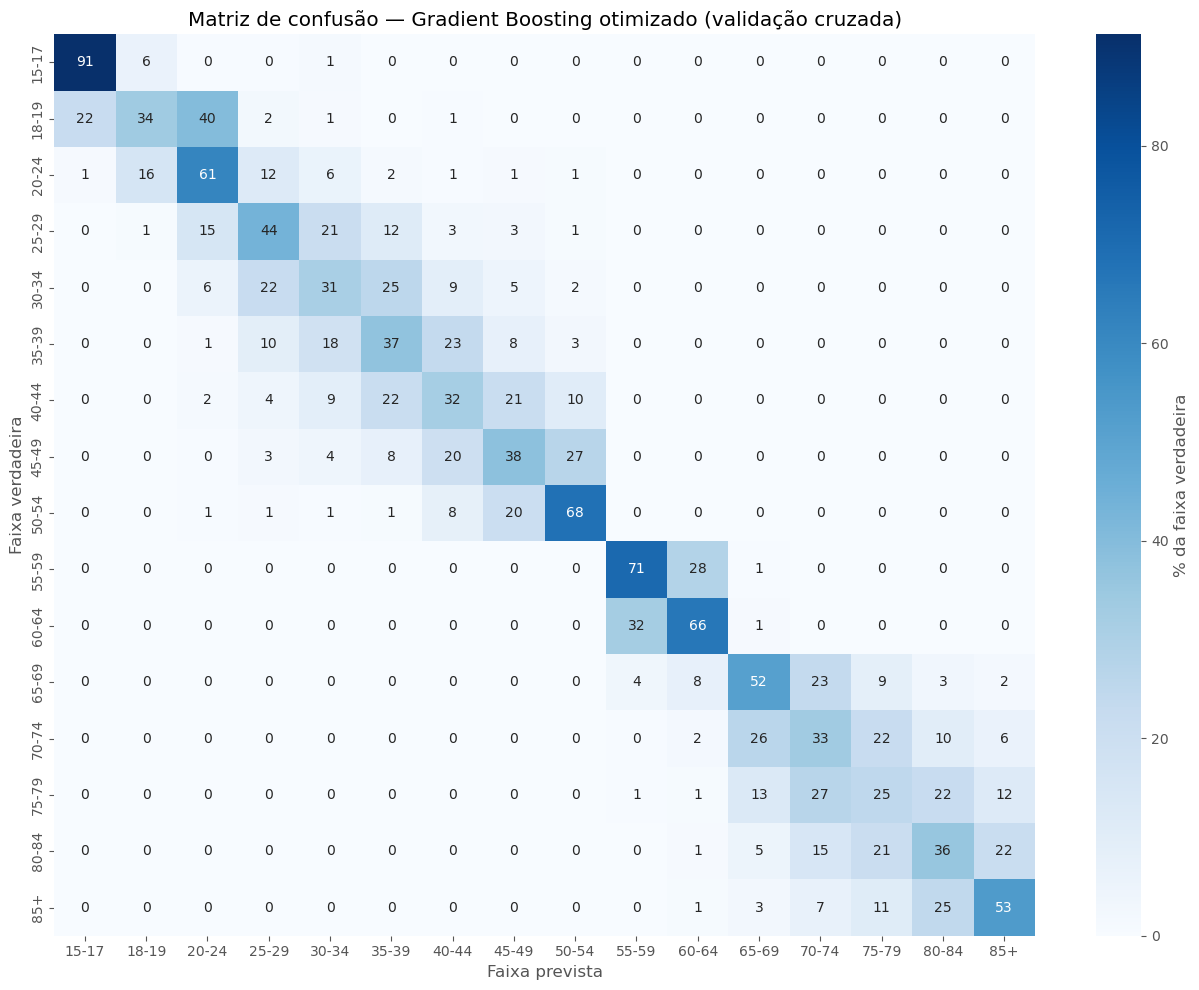

,Faixa,Nº pessoas,F1
0,15-17,207,0.855
1,18-19,172,0.371
2,20-24,399,0.593
3,25-29,377,0.400
4,30-34,449,0.299
5,35-39,647,0.369
6,40-44,859,0.345
7,45-49,862,0.397
8,50-54,905,0.658
9,55-59,1014,0.679


Acerto exato:                47.9%
Erro de 1 faixa (vizinha):   37.0%
Erro de 2 faixas:            10.7%
Erro de 3 ou mais faixas:    4.4%
Erros que cruzam os 55 anos: 5 pessoas (0.0%)


In [5]:
gb_final = HistGradientBoostingClassifier(max_iter=500, early_stopping=True, validation_fraction=0.1,
                                          n_iter_no_change=20, class_weight='balanced',
                                          random_state=RANDOM_STATE, **MELHORES_PARAMS_GB)

prev_cv = cross_val_predict(gb_final, X, y, cv=cv, n_jobs=-1)
prev_cv = np.maximum(prev_cv, faixa_min)          # correção pela idade mínima
print(f"Macro F1 do Gradient Boosting otimizado (validação cruzada): {f1_score(y, prev_cv, average='macro'):.4f}")

# 1) Matriz de confusão (% por faixa verdadeira)
matriz = confusion_matrix(y, prev_cv, normalize='true') * 100
plt.figure(figsize=(13, 10))
sns.heatmap(matriz, annot=True, fmt='.0f', cmap='Blues',
            xticklabels=AGE_LABELS, yticklabels=AGE_LABELS, cbar_kws={'label': '% da faixa verdadeira'})
plt.xlabel('Faixa prevista')
plt.ylabel('Faixa verdadeira')
plt.title('Matriz de confusão — Gradient Boosting otimizado (validação cruzada)')
plt.tight_layout()
plt.show()

# 2) F1 por faixa
f1_faixa = pd.DataFrame({'Faixa': AGE_LABELS,
                         'Nº pessoas': y.value_counts().sort_index().values,
                         'F1': f1_score(y, prev_cv, average=None).round(3)})
display(f1_faixa)

# 3) Distância dos erros
distancia = np.abs(prev_cv - y.values)
cruza_55 = (prev_cv >= 9) != (y.values >= 9)
print(f"Acerto exato:                {(distancia == 0).mean():.1%}")
print(f"Erro de 1 faixa (vizinha):   {(distancia == 1).mean():.1%}")
print(f"Erro de 2 faixas:            {(distancia == 2).mean():.1%}")
print(f"Erro de 3 ou mais faixas:    {(distancia >= 3).mean():.1%}")
print(f"Erros que cruzam os 55 anos: {cruza_55.sum()} pessoas ({cruza_55.mean():.1%})")

> **Conclusão:** o modelo obtém um Macro F1 de 0,475. Acerta exatamente em 47,9% dos casos e 84,9% das previsões ficam a no máximo uma faixa da verdadeira; apenas 4,4% erram por três ou mais faixas, e só 5 pessoas são colocadas do lado errado do limite dos 55 anos.
>
> O F1 é mais elevado nas faixas junto a uma fronteira, que têm apenas um vizinho com que se confundir: 15-17 (0,86), 55-59 (0,68), 50-54 (0,66) e 60-64 (0,65). É mais baixo nas faixas intermédias de cada grupo, em especial 75-79 (0,27) e 30-34 (0,30), cujos perfis de saúde e estilo de vida são muito semelhantes aos das faixas vizinhas. A faixa 18-19 é frequentemente confundida com 20-24 (40%) e 15-17 (22%), o que reflete uma fase de transição (fim dos estudos secundários) que dura apenas dois anos.

## 6. Submissão do Gradient Boosting (sub. 4)

O modelo é o **Gradient Boosting** com os hiperparâmetros da secção 4, treinado com todo o conjunto de treino. As previsões para o teste são corrigidas pela idade mínima e guardadas no formato da competição.

In [6]:
gb_final.fit(X, y)
previsoes_teste = np.maximum(gb_final.predict(X_test), faixa_min_test)

print(f"Nº de árvores do modelo: {gb_final.n_iter_}")
print(f"Previsões corrigidas pela idade mínima: {(gb_final.predict(X_test) < faixa_min_test).sum()}")

# Comparação da distribuição das previsões com a do treino
distribuicao = pd.DataFrame({
    'Treino (%)': y.value_counts(normalize=True).sort_index().values * 100,
    'Previsões no teste (%)': pd.Series(previsoes_teste).value_counts(normalize=True)
                                .reindex(range(16), fill_value=0).values * 100,
}, index=AGE_LABELS).round(1)
display(distribuicao)

gerar_submissao(previsoes_teste, 'sub04_gradient_boosting_otimizado.csv')

Nº de árvores do modelo: 156


Previsões corrigidas pela idade mínima: 5


,Treino (%),Previsões no teste (%)
15-17,1.9,1.7
18-19,1.6,1.5
20-24,3.6,3.9
25-29,3.4,4.4
30-34,4.1,4.9
35-39,5.9,5.4
40-44,7.8,6.6
45-49,7.9,8.1
50-54,8.3,8.0
55-59,9.3,10.4


Submissão guardada em ../submissions/sub04_gradient_boosting_otimizado.csv


> **Conclusão:** este modelo (156 árvores) faz apenas 5 previsões no teste abaixo da idade mínima, que são corrigidas. As previsões distribuem-se pelas 16 faixas em proporções semelhantes às do treino (diferença máxima de 1,1 pontos percentuais, na faixa 55-59), sem nenhuma faixa ignorada. O ficheiro `sub04_gradient_boosting_otimizado.csv` corresponde à submissão 4.

## 7. XGBoost e Combinação de Modelos

### 7.1 XGBoost e média com o Gradient Boosting

O **XGBoost** é outra implementação de *gradient boosting*: tal como o Gradient Boosting da secção 4, constrói árvores em sequência, cada uma a corrigir os erros das anteriores. Diferencia-se por, em cada árvore, usar apenas uma amostra aleatória das pessoas (`subsample=0.8`) e das variáveis (`colsample_bytree=0.5`), o que torna o modelo mais robusto e faz com que erre em casos diferentes do Gradient Boosting.

Parâmetros usados:

| Hiperparâmetro | O que controla | Valor |
|---|---|---|
| `n_estimators` | nº de árvores | 350 |
| `learning_rate` | quanto cada nova árvore corrige as anteriores | 0,05 |
| `max_depth` | profundidade máxima de cada árvore | 4 |
| `min_child_weight` | peso mínimo de pessoas por folha | 3 |
| `subsample` | % de pessoas usadas em cada árvore | 0,8 |
| `colsample_bytree` | % de variáveis usadas em cada árvore | 0,5 |

O XGBoost não tem a opção `class_weight='balanced'`; o mesmo efeito obtém-se com **pesos por pessoa** (`compute_sample_weight('balanced')`), maiores nas faixas com menos pessoas.

Obtemos as **probabilidades** de cada faixa por validação cruzada (mesmas 5 partes) para o XGBoost e para o Gradient Boosting otimizado, e testamos também a **média das probabilidades** dos dois modelos. Todas as previsões incluem a correção pela idade mínima.


In [7]:
xgb = XGBClassifier(n_estimators=350, learning_rate=0.05, max_depth=4, min_child_weight=3,
                    subsample=0.8, colsample_bytree=0.5, n_jobs=-1, random_state=RANDOM_STATE)
pesos = compute_sample_weight('balanced', y)

inicio = time.time()
proba_xgb = cross_val_predict(xgb, X.values, y, cv=cv, method='predict_proba',
                              params={'sample_weight': pesos})
print(f"XGBoost: {time.time() - inicio:.0f} s")

inicio = time.time()
proba_gb = cross_val_predict(gb_final, X, y, cv=cv, method='predict_proba', n_jobs=-1)
print(f"Gradient Boosting: {time.time() - inicio:.0f} s")

proba_media = (proba_gb + proba_xgb) / 2

tabela = []
for nome, proba in [('Gradient Boosting (sub. 4)', proba_gb),
                    ('XGBoost', proba_xgb),
                    ('Média GB + XGBoost', proba_media)]:
    prev = np.maximum(proba.argmax(axis=1), faixa_min)          # faixa mais provável + correção
    notas = [f1_score(y.iloc[va], prev[va], average='macro') for _, va in cv.split(X, y)]
    tabela.append({'Modelo': nome,
                   'Macro F1 (com correção)': f1_score(y, prev, average='macro'),
                   'Desvio padrão': np.std(notas),
                   'Acerto exato': (prev == y).mean(),
                   'A ≤1 faixa': (np.abs(prev - y) <= 1).mean()})

display(pd.DataFrame(tabela).round(4))
print(f"O GB e o XGBoost preveem a mesma faixa em {(proba_gb.argmax(axis=1) == proba_xgb.argmax(axis=1)).mean():.1%} das pessoas")

XGBoost: 51 s


Gradient Boosting: 40 s


,Modelo,Macro F1 (com correção),Desvio padrão,Acerto exato,A ≤1 faixa
0,Gradient Boosting (sub. 4),0.4752,0.0077,0.4791,0.8488
1,XGBoost,0.4796,0.0146,0.4810,0.8536
2,Média GB + XGBoost,0.4768,0.0089,0.4803,0.8528


O GB e o XGBoost preveem a mesma faixa em 77.4% das pessoas


> **Conclusão:** o XGBoost obtém um Macro F1 de 0,480 ± 0,015, ligeiramente acima do Gradient Boosting otimizado (0,475 ± 0,008), mas a diferença está dentro do desvio padrão e o XGBoost é menos estável entre partes. A média das probabilidades dos dois modelos (0,477) não traz ganho claro. Os dois modelos preveem a mesma faixa em 77,4% das pessoas: discordam sobretudo em casos de fronteira entre faixas vizinhas, o que motiva a combinação com um regressor (secção 7.2).

### 7.2 Combinação de classificador e regressor

A faixa etária é uma variável **ordinal**: as faixas têm ordem e a maioria dos erros dá-se entre faixas vizinhas (secção 5). Um classificador trata as 16 faixas como categorias independentes; um **regressor** prevê a faixa como um número contínuo (ex.: 9,6), que é arredondado para a faixa mais próxima, tirando partido da ordem.

Combinamos os dois com uma regra baseada na **confiança** do classificador (a sua probabilidade máxima):

- se a confiança for **igual ou superior a um limiar**, usa-se a faixa prevista pelo classificador;
- caso contrário (o classificador hesita entre várias faixas), usa-se a faixa prevista pelo regressor;
- por fim, aplica-se a correção pela idade mínima.

As funções `combinar_com` e `aninhado`, definidas aqui, são reutilizadas nas secções 7.5 e 7.7.

O regressor é um `HistGradientBoostingRegressor` com os mesmos hiperparâmetros do Gradient Boosting otimizado e com pesos por pessoa, para dar a mesma importância a todas as faixas.

Para que a avaliação seja honesta, o **limiar é escolhido dentro da validação cruzada**: em cada uma das 5 partes, testam-se os limiares {0,30; 0,35; ...; 0,55} nas 4 partes de treino e o melhor é aplicado à parte de validação. Testamos a combinação com os três classificadores da secção 7.1.


In [8]:
reg = HistGradientBoostingRegressor(max_iter=500, early_stopping=True, validation_fraction=0.1,
                                    n_iter_no_change=20, random_state=RANDOM_STATE, **MELHORES_PARAMS_GB)
valor_reg = cross_val_predict(reg, X, y, cv=cv, n_jobs=-1, params={'sample_weight': pesos})
prev_reg = np.clip(np.round(valor_reg), 0, 15).astype(int)          # número → faixa (0 a 15)
print(f"Regressor sozinho (com correção): {f1_score(y, np.maximum(prev_reg, faixa_min), average='macro'):.4f}")

LIMIARES = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55]
partes = list(cv.split(X, y))


def combinar_com(proba, alternativa, limiar):
    """Faixa mais provável se a confiança >= limiar; senão, a alternativa (ex.: o regressor). Aplica a correção."""
    confiante = proba.max(axis=1) >= limiar
    return np.maximum(np.where(confiante, proba.argmax(axis=1), alternativa), faixa_min)


def aninhado(proba, alternativa):
    """Limiar escolhido nas 4 partes de treino e aplicado à 5.ª (avaliação honesta)."""
    prev_comb = np.zeros(len(y), dtype=int)
    escolhidos = []
    for treino, validacao in partes:
        f1_limiar = {t: f1_score(y.iloc[treino], combinar_com(proba, alternativa, t)[treino], average='macro')
                     for t in LIMIARES}
        melhor = max(f1_limiar, key=f1_limiar.get)
        escolhidos.append(melhor)
        prev_comb[validacao] = combinar_com(proba, alternativa, melhor)[validacao]
    return prev_comb, escolhidos


prev_base = np.maximum(proba_gb.argmax(axis=1), faixa_min)           # Gradient Boosting (sub. 4)
resultados = []
for nome, proba in [('GB + regressor', proba_gb), ('XGBoost + regressor', proba_xgb),
                    ('Média GB + XGBoost + regressor', proba_media)]:
    prev_comb, escolhidos = aninhado(proba, prev_reg)
    ganhos = [f1_score(y.iloc[v], prev_comb[v], average='macro') - f1_score(y.iloc[v], prev_base[v], average='macro')
              for _, v in partes]
    resultados.append({'Combinação': nome,
                       'Macro F1': f1_score(y, prev_comb, average='macro'),
                       'Limiares escolhidos': escolhidos,
                       'Ganho por parte vs sub. 4': np.round(ganhos, 3).tolist(),
                       'Acerto exato': (prev_comb == y).mean(),
                       'A ≤1 faixa': (np.abs(prev_comb - y) <= 1).mean()})

print(f"Referência — GB otimizado + correção (sub. 4): {f1_score(y, prev_base, average='macro'):.4f}")
display(pd.DataFrame(resultados).round(4))

# Efeito do limiar na melhor combinação (XGBoost + regressor)
curva = pd.DataFrame({'Limiar': LIMIARES,
                      'Macro F1': [f1_score(y, combinar_com(proba_xgb, prev_reg, t), average='macro') for t in LIMIARES],
                      '% decidido pelo regressor': [(proba_xgb.max(axis=1) < t).mean() * 100 for t in LIMIARES]})
display(curva.round(4))


Regressor sozinho (com correção): 0.4302
Referência — GB otimizado + correção (sub. 4): 0.4752


,Combinação,Macro F1,Limiares escolhidos,Ganho por parte vs sub. 4,Acerto exato,A ≤1 faixa
0,GB + regressor,0.4772,"[0.3, 0.4, 0.4, 0.4, 0.4]","[0.01, 0.006, -0.001, 0.0, -0.005]",0.4759,0.8680
1,XGBoost + regressor,0.4888,"[0.35, 0.35, 0.35, 0.35, 0.35]","[0.044, 0.018, -0.004, 0.012, -0.001]",0.4856,0.8678
2,Média GB + XGBoost + regressor,0.4802,"[0.35, 0.3, 0.4, 0.35, 0.35]","[0.027, 0.005, -0.005, 0.006, -0.007]",0.4791,0.8680


,Limiar,Macro F1,% decidido pelo regressor
0,0.30,0.4851,10.8739
1,0.35,0.4888,24.3295
2,0.40,0.4862,38.2138
3,0.45,0.4801,50.1186
4,0.50,0.4783,60.7371
5,0.55,0.4709,69.4673


> **Conclusão:** o regressor sozinho tem um desempenho inferior (Macro F1 = 0,430), mas combinado com um classificador melhora o resultado em todos os casos. A melhor combinação é **XGBoost + regressor**, com Macro F1 = 0,489 face a 0,475 do Gradient Boosting (+0,014). O limiar foi escolhido dentro da validação cruzada e foi o mesmo (0,35) nas 5 partes, o que indica uma escolha estável. Com este limiar, cerca de 24% das pessoas, aquelas em que o classificador hesita, são decididas pelo regressor.
>
> O ganho não é uniforme: é claro em três partes (+0,044, +0,018 e +0,012) e nulo nas outras duas (−0,004 e −0,001), pelo que deve ser interpretado com cautela. A melhoria vem sobretudo da ordem das faixas: o regressor, ao prever um número, coloca os casos duvidosos entre as faixas mais prováveis em vez de escolher uma delas quase ao acaso. As outras combinações (GB + regressor: 0,477; média + regressor: 0,480) ficam dentro do ruído face ao Gradient Boosting.


### 7.3 Submissão 5

A combinação XGBoost + regressor (limiar 0,35), treinada com todo o conjunto de treino, foi submetida ao Kaggle como **submissão 5** (`sub05_xgboost_regressor.csv`): Macro F1 de 0,489 na validação cruzada e 0,48 no Kaggle (secção 8.1). No teste, 26% das previsões foram decididas pelo regressor, próximo dos 24% da validação. As previsões coincidiram com as da submissão 4 em 70% das pessoas (95% a ≤ 1 faixa).

### 7.4 Modelo ordinal (15 perguntas "a faixa é maior do que k?")

Os classificadores usados até aqui tratam as 16 faixas como categorias sem ordem: confundir 60-64 com 65-69 conta como um erro tão grave como confundir 60-64 com 15-17. Mas as faixas têm ordem, e a análise de erros (secção 5) mostrou que a maior parte dos erros acontece entre faixas vizinhas.

O **modelo ordinal** (Frank & Hall, 2001) aproveita essa ordem. Em vez de uma pergunta com 16 respostas, faz **15 perguntas de sim/não**, uma por cada fronteira entre faixas:

| Pergunta | Separa |
|---|---|
| k = 0: a faixa é maior do que 15-17? | 15-17 \| 18-19 em diante |
| k = 8: a faixa é maior do que 50-54? | até 50-54 \| 55-59 em diante |
| k = 14: a faixa é maior do que 80-84? | até 80-84 \| 85+ |

Cada pergunta é um **XGBoost binário** treinado com **todas** as pessoas (dois grupos grandes em vez de 16 pequenos). A probabilidade de cada faixa é a **diferença entre duas perguntas seguidas**:

$$P(\text{faixa} = k) = P(\text{faixa} > k-1) - P(\text{faixa} > k)$$

Exemplo: se P(> 55-59) = 0,62 e P(> 60-64) = 0,25, então P(60-64) = 0,62 − 0,25 = 0,37.

Detalhes:
- os 15 modelos são independentes, por isso a sequência P(> k) pode subir ligeiramente de uma pergunta para a seguinte, o que daria probabilidades negativas. Força-se a sequência a **nunca subir**;
- cada pessoa leva o peso `balanced` da sua faixa (das 16), para as faixas pequenas continuarem a contar;
- o resultado varia um pouco com a semente aleatória, por isso faz-se a **média de 5 sementes**.

Referência: Frank, E. & Hall, M. (2001). *A Simple Approach to Ordinal Classification*. ECML 2001, LNCS 2167, pp. 145–156.


In [9]:
def probabilidades_ordinais(X_treino, y_treino, X_prever, semente):
    """15 perguntas 'a faixa é maior do que k?' -> probabilidades das 16 faixas."""
    pesos_treino = compute_sample_weight('balanced', y_treino)        # pesos das 16 faixas, não das 2 respostas
    acima = np.zeros((len(X_prever), 15))                               # acima[:, k] = P(faixa > k)
    for k in range(15):
        modelo = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, min_child_weight=3,
                               subsample=0.8, colsample_bytree=0.5, n_jobs=-1, random_state=semente)
        modelo.fit(X_treino, (y_treino > k).astype(int), sample_weight=pesos_treino)
        acima[:, k] = modelo.predict_proba(X_prever)[:, 1]
    acima = np.minimum.accumulate(acima, axis=1)                        # P(faixa > k) não pode subir com k
    proba = np.column_stack([1 - acima[:, 0],                           # faixa 0: não passa a 1.ª pergunta
                             acima[:, :-1] - acima[:, 1:],              # faixas 1-14: diferença de perguntas seguidas
                             acima[:, -1]])                             # faixa 15: passa a última
    proba = np.clip(proba, 1e-6, None)
    return proba / proba.sum(axis=1, keepdims=True)


SEMENTES = [42, 1, 2, 3, 4]
proba_ord = np.zeros((len(X), 16))
inicio = time.time()
for semente in SEMENTES:
    proba_semente = np.zeros((len(X), 16))
    for treino, validacao in partes:
        proba_semente[validacao] = probabilidades_ordinais(X.values[treino], y.values[treino],
                                                           X.values[validacao], semente)
    proba_ord += proba_semente / len(SEMENTES)
    f1_semente = f1_score(y, np.maximum(proba_semente.argmax(axis=1), faixa_min), average='macro')
    print(f'Semente {semente:>2}: Macro F1 = {f1_semente:.4f}  ({time.time() - inicio:.0f} s)')

prev_xgb = np.maximum(proba_xgb.argmax(axis=1), faixa_min)
prev_ord = np.maximum(proba_ord.argmax(axis=1), faixa_min)

comparacao = pd.DataFrame({
    'Macro F1': [f1_score(y, p, average='macro') for p in [prev_xgb, prev_ord]],
    'Desvio entre partes': [np.std([f1_score(y.iloc[v], p[v], average='macro') for _, v in partes])
                            for p in [prev_xgb, prev_ord]],
    'Acerto exato (%)': [100 * np.mean(p == y) for p in [prev_xgb, prev_ord]],
    'A ≤ 1 faixa (%)': [100 * np.mean(np.abs(p - y) <= 1) for p in [prev_xgb, prev_ord]],
    'Confiança ≥ 0,35 (%)': [100 * np.mean(p.max(axis=1) >= 0.35) for p in [proba_xgb, proba_ord]],
}, index=['XGBoost (16 faixas)', 'Ordinal (15 perguntas, 5 sementes)']).round(4)
display(comparacao)

f1_faixa = pd.DataFrame({'XGBoost': f1_score(y, prev_xgb, average=None),
                         'Ordinal': f1_score(y, prev_ord, average=None)}, index=AGE_LABELS)
display(f1_faixa.round(2).T)


Semente 42: Macro F1 = 0.5008  (41 s)


Semente  1: Macro F1 = 0.4977  (83 s)


Semente  2: Macro F1 = 0.5023  (124 s)


Semente  3: Macro F1 = 0.4984  (166 s)


Semente  4: Macro F1 = 0.4983  (208 s)


,Macro F1,Desvio entre partes,Acerto exato (%),A ≤ 1 faixa (%),"Confiança ≥ 0,35 (%)"
XGBoost (16 faixas),0.4796,0.0146,48.1025,85.3585,75.6705
"Ordinal (15 perguntas, 5 sementes)",0.5039,0.0097,50.0274,87.8854,88.7977


,15-17,18-19,20-24,25-29,30-34,35-39,40-44,45-49,50-54,55-59,60-64,65-69,70-74,75-79,80-84,85+
XGBoost,0.86,0.42,0.59,0.40,0.29,0.37,0.35,0.42,0.66,0.67,0.63,0.52,0.36,0.29,0.35,0.51
Ordinal,0.86,0.47,0.63,0.42,0.34,0.38,0.38,0.42,0.67,0.69,0.68,0.56,0.38,0.31,0.38,0.50


> **Conclusão:** o modelo ordinal obtém um Macro F1 de **0,504** sozinho (com correção), contra 0,480 do XGBoost normal: **+0,024 com os mesmos hiperparâmetros**, só por mudar a forma como o problema é colocado. Com uma única semente, o resultado varia entre 0,498 e 0,502; a média das 5 sementes é melhor do que qualquer semente isolada e mais estável entre partes (desvio 0,010 contra 0,015). O acerto exato sobe de 48,1% para 50,0% e as previsões a ≤ 1 faixa de 85,4% para 87,9%: quando erra, o modelo ordinal erra mais perto. O F1 é igual ou superior em 15 das 16 faixas, com os maiores ganhos em 18-19 (0,42 → 0,47), 30-34 (0,29 → 0,34) e 60-64 (0,63 → 0,68). O modelo também fica muito mais confiante: a faixa mais provável tem pelo menos 0,35 de probabilidade em 88,8% das pessoas (contra 75,7%), o que significa que o regressor vai ser chamado menos vezes.

### 7.5 Modelo ordinal + regressor

Aplicamos ao modelo ordinal a mesma combinação da secção 7.2: quando a confiança do modelo ordinal é igual ou superior ao limiar, usa-se a sua faixa; caso contrário, usa-se o regressor; no fim, aplica-se a correção pela idade mínima. O limiar volta a ser escolhido dentro da validação cruzada (nas 4 partes de treino, aplicado à 5.ª), para a avaliação ser honesta. A comparação é feita com a combinação da submissão 5 (XGBoost + regressor).


In [10]:
prev_sub5, limiares_sub5 = aninhado(proba_xgb, prev_reg)
prev_sub6, limiares_sub6 = aninhado(proba_ord, prev_reg)

resultados = []
for nome, prev, limiares in [('XGBoost + regressor (sub. 5)', prev_sub5, limiares_sub5),
                             ('Ordinal + regressor', prev_sub6, limiares_sub6)]:
    resultados.append({'Combinação': nome,
                       'Macro F1': f1_score(y, prev, average='macro'),
                       'Limiares escolhidos': limiares,
                       'F1 por parte': [round(f1_score(y.iloc[v], prev[v], average='macro'), 3) for _, v in partes],
                       'Acerto exato': (prev == y).mean(),
                       'A ≤1 faixa': (np.abs(prev - y) <= 1).mean()})
display(pd.DataFrame(resultados).round(4))
print(f"Decididas pelo regressor (limiar 0,35): ordinal {(proba_ord.max(axis=1) < 0.35).mean() * 100:.1f}% | "
      f"XGBoost {(proba_xgb.max(axis=1) < 0.35).mean() * 100:.1f}%")


,Combinação,Macro F1,Limiares escolhidos,F1 por parte,Acerto exato,A ≤1 faixa
0,XGBoost + regressor (sub. 5),0.4888,"[0.35, 0.35, 0.35, 0.35, 0.35]","[0.517, 0.493, 0.481, 0.474, 0.479]",0.4856,0.8678
1,Ordinal + regressor,0.5051,"[0.35, 0.35, 0.35, 0.35, 0.35]","[0.519, 0.516, 0.497, 0.497, 0.495]",0.5000,0.8811


Decididas pelo regressor (limiar 0,35): ordinal 11.2% | XGBoost 24.3%


> **Conclusão:** a combinação do modelo ordinal com o regressor obtém um Macro F1 de **0,505**, contra 0,489 da combinação da submissão 5 (XGBoost + regressor): **+0,016**, e melhor nas **5 partes** da validação (o F1 por parte passa de 0,474–0,517 para 0,495–0,519). O limiar escolhido é 0,35 em todas as partes, o mesmo da secção 7.2. Agora o regressor só decide **11,2%** das pessoas (contra ~24% com o XGBoost), porque o modelo ordinal já tira partido da ordem das faixas. O ganho do regressor é por isso pequeno (0,504 → 0,505), mas consistente. O acerto exato chega a 50,0% e 88,1% das previsões ficam a ≤ 1 faixa.


### 7.6 Submissão 6

A combinação modelo ordinal + regressor (limiar 0,35), treinada com todo o conjunto de treino, foi submetida ao Kaggle como **submissão 6** (`sub06_ordinal_regressor.csv`): Macro F1 de 0,505 na validação cruzada e 0,49 no Kaggle (secção 8.1). No teste, 12,9% das previsões foram decididas pelo regressor, próximo dos 11,2% da validação. As previsões coincidiram com as da submissão 5 em 80% das pessoas (98% a ≤ 1 faixa).

### 7.7 Três modelos ordinais e a regra da mediana

O modelo ordinal da secção 7.4 responde às 15 perguntas "a faixa é maior do que k?" com o XGBoost. Repetimos as mesmas perguntas com dois algoritmos de *boosting* diferentes, **LightGBM** (4 sementes) e **HistGradientBoosting** (2 sementes), com parâmetros equivalentes (300 árvores, `learning_rate=0.05`, 15 folhas) e os mesmos pesos. Como os três erram em pessoas um pouco diferentes, a **média das probabilidades** compensa parte dos erros de cada um.

Testamos também uma alternativa ao regressor para as pessoas em que o modelo está pouco confiante: a **mediana** das probabilidades, ou seja, a faixa onde a probabilidade acumulada passa os 50%. Por exemplo, com P(50-54) = 0,30, P(55-59) = 0,25 e P(60-64) = 0,30, a faixa mais provável está empatada, mas a mediana é 55-59, a faixa "do meio". É uma regra que aproveita a ordem das faixas e dispensa um modelo extra.

Como na secção 7.5 (com as funções `combinar_com` e `aninhado` da 7.2), o limiar de confiança é escolhido nas 4 partes de treino e aplicado à 5.ª. Como o cálculo demora cerca de 20 minutos, as previsões são guardadas em `oof_ordinal_lgbm_hgb.csv` e reutilizadas nas execuções seguintes.

*Nota técnica:* o `LightGBM` (instalado com `pip`) traz a sua própria cópia da biblioteca de paralelismo OpenMP, diferente da usada pelo scikit-learn e pelo XGBoost. Com as duas carregadas, o kernel pode morrer (*segmentation fault*); por isso o `import` está nesta secção e não na secção 1.

In [11]:
from lightgbm import LGBMClassifier   # importado só aqui (ver nota no markdown)

def probabilidades_ordinais_modelo(criar_modelo, X_treino, y_treino, X_prever):
    """Igual à probabilidades_ordinais (7.4), mas com qualquer classificador binário."""
    pesos_treino = compute_sample_weight('balanced', y_treino)
    acima = np.zeros((len(X_prever), 15))
    for k in range(15):
        modelo = criar_modelo()
        modelo.fit(X_treino, (y_treino > k).astype(int), sample_weight=pesos_treino)
        acima[:, k] = modelo.predict_proba(X_prever)[:, 1]
    acima = np.minimum.accumulate(acima, axis=1)
    proba = np.column_stack([1 - acima[:, 0], acima[:, :-1] - acima[:, 1:], acima[:, -1]])
    proba = np.clip(proba, 1e-6, None)
    return proba / proba.sum(axis=1, keepdims=True)


MODELOS_ORDINAIS = {
    'LightGBM': (lambda s: LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=20,
                                          subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1,
                                          verbose=-1, n_jobs=-1, random_state=s), [42, 1, 2, 3]),
    'HGB': (lambda s: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                                     min_samples_leaf=20, l2_regularization=1,
                                                     early_stopping=False, random_state=s), [42, 1]),
}

FICHEIRO_OOF = os.path.join(DATA_DIR, 'oof_ordinal_lgbm_hgb.csv')
if os.path.exists(FICHEIRO_OOF):
    oof_ordinais = pd.read_csv(FICHEIRO_OOF, index_col='PID')
    print(f'Previsões lidas de {FICHEIRO_OOF}')
else:
    inicio = time.time()
    colunas = []
    for nome, (criar, sementes) in MODELOS_ORDINAIS.items():
        proba = np.zeros((len(X), 16))
        for semente in sementes:
            for treino, validacao in partes:
                proba[validacao] += probabilidades_ordinais_modelo(lambda: criar(semente), X.values[treino], y.values[treino],
                                                                   X.values[validacao]) / len(sementes)
        colunas.append(pd.DataFrame(proba, index=X.index, columns=[f'{nome}_{k}' for k in range(16)]))
        print(f'{nome}: {time.time() - inicio:.0f} s')
    oof_ordinais = pd.concat(colunas, axis=1)
    oof_ordinais.to_csv(FICHEIRO_OOF)

proba_lgbm = oof_ordinais[[f'LightGBM_{k}' for k in range(16)]].values
proba_hgb = oof_ordinais[[f'HGB_{k}' for k in range(16)]].values
proba_3 = (proba_ord + proba_lgbm + proba_hgb) / 3                     # média dos 3 modelos ordinais


def mediana(proba):
    """Faixa onde a probabilidade acumulada passa os 50%."""
    return (np.cumsum(proba, axis=1) < 0.5).sum(axis=1)


variantes = {
    'Ordinal XGBoost + regressor (sub. 6)': aninhado(proba_ord, prev_reg),
    'Ordinal XGBoost + mediana': aninhado(proba_ord, mediana(proba_ord)),
    'Ordinal LightGBM + mediana': aninhado(proba_lgbm, mediana(proba_lgbm)),
    'Ordinal HGB + mediana': aninhado(proba_hgb, mediana(proba_hgb)),
    'Média dos 3 + regressor': aninhado(proba_3, prev_reg),
    'Média dos 3 + mediana': aninhado(proba_3, mediana(proba_3)),
}
resultados = []
for nome, (prev, limiares) in variantes.items():
    resultados.append({'Variante': nome,
                       'Macro F1': f1_score(y, prev, average='macro'),
                       'Limiares escolhidos': limiares,
                       'F1 por parte': [round(f1_score(y.iloc[v], prev[v], average='macro'), 3) for _, v in partes],
                       'Acerto exato': (prev == y).mean(),
                       'A ≤1 faixa': (np.abs(prev - y) <= 1).mean()})
display(pd.DataFrame(resultados).round(4))
print(f'Concordância entre os 3 modelos ordinais (mesma faixa mais provável): '
      f'{np.mean((proba_ord.argmax(1) == proba_lgbm.argmax(1)) & (proba_ord.argmax(1) == proba_hgb.argmax(1))) * 100:.1f}%')


Previsões lidas de ../data/oof_ordinal_lgbm_hgb.csv


,Variante,Macro F1,Limiares escolhidos,F1 por parte,Acerto exato,A ≤1 faixa
0,Ordinal XGBoost + regressor (sub. 6),0.5051,"[0.35, 0.35, 0.35, 0.35, 0.35]","[0.519, 0.516, 0.497, 0.497, 0.495]",0.5000,0.8811
1,Ordinal XGBoost + mediana,0.5065,"[0.35, 0.35, 0.35, 0.35, 0.35]","[0.52, 0.512, 0.498, 0.501, 0.499]",0.5020,0.8855
2,Ordinal LightGBM + mediana,0.5044,"[0.4, 0.45, 0.45, 0.45, 0.4]","[0.515, 0.507, 0.507, 0.494, 0.497]",0.5011,0.8945
3,Ordinal HGB + mediana,0.5006,"[0.45, 0.4, 0.4, 0.45, 0.45]","[0.516, 0.499, 0.509, 0.483, 0.494]",0.4940,0.8882
4,Média dos 3 + regressor,0.5060,"[0.3, 0.3, 0.3, 0.4, 0.3]","[0.524, 0.513, 0.511, 0.49, 0.49]",0.5008,0.8842
5,Média dos 3 + mediana,0.5089,"[0.4, 0.4, 0.4, 0.4, 0.45]","[0.526, 0.512, 0.511, 0.497, 0.496]",0.5018,0.8911


Concordância entre os 3 modelos ordinais (mesma faixa mais provável): 77.7%


> **Conclusão:** os três modelos ordinais têm desempenhos parecidos quando usados sozinhos com a mediana: XGBoost 0,5065, LightGBM 0,5044 e HGB 0,5006. Concordam na faixa mais provável em 77,7% das pessoas e, nas restantes, erram de forma diferente. Por isso, a **média dos três** é melhor do que qualquer um deles: **0,5089 com a mediana**, contra 0,5051 do modelo da submissão 6. O ganho é pequeno (+0,004), mas a média dos três é a melhor ou está empatada com a melhor nas três primeiras partes. A mediana funciona melhor do que o regressor em quase todos os casos (XGBoost: 0,5065 contra 0,5051; média dos 3: 0,5089 contra 0,5060). Aproveita a ordem das faixas sem precisar de um modelo extra. O limiar escolhido (0,40 em 4 das 5 partes) é mais alto do que com o regressor, porque a mediana é uma alternativa mais segura do que o regressor quando o modelo hesita. Com 89,1% das previsões a ≤ 1 faixa, é também a variante com os erros mais pequenos.

### 7.8 Modelo final e submissão

Os três modelos ordinais (XGBoost com 5 sementes, LightGBM com 4 e HistGradientBoosting com 2) são treinados com todo o conjunto de treino. No teste, usa-se a média das suas probabilidades: a faixa mais provável quando a confiança é igual ou superior a **0,40** (o limiar escolhido em 4 das 5 partes na secção 7.7); caso contrário, a mediana. Por fim, aplica-se a correção pela idade mínima.

Este modelo foi submetido ao Kaggle (submissão 7, Macro F1 público = 0,51) a partir de um script com o mesmo código; a célula confirma que as previsões do notebook são iguais às do ficheiro submetido.


In [12]:
LIMIAR_FINAL = 0.40
FICHEIRO_SUB = 'sub07_ordinal_3modelos_mediana.csv'
inicio = time.time()

# Os 3 modelos ordinais treinados com todo o treino (mesmas sementes da validação)
proba_teste = {'XGBoost': np.mean([probabilidades_ordinais(X.values, y.values, X_test.values, s) for s in SEMENTES], axis=0)}
for nome, (criar, sementes) in MODELOS_ORDINAIS.items():
    proba_teste[nome] = np.mean([probabilidades_ordinais_modelo(lambda: criar(s), X.values, y.values, X_test.values)
                                 for s in sementes], axis=0)
    print(f'{nome}: {time.time() - inicio:.0f} s')
proba_3_teste = np.mean(list(proba_teste.values()), axis=0)

# Combinação: faixa mais provável se confiança >= 0,40; senão, a mediana; depois a correção
confiante = proba_3_teste.max(axis=1) >= LIMIAR_FINAL
previsoes_sem_correcao = np.where(confiante, proba_3_teste.argmax(axis=1), mediana(proba_3_teste))
previsoes_teste = np.maximum(previsoes_sem_correcao, faixa_min_test)
print(f'Faixa mais provável: {confiante.mean() * 100:.1f}% | mediana: {(~confiante).mean() * 100:.1f}% | '
      f'corrigidas pela idade mínima: {(previsoes_teste != previsoes_sem_correcao).sum()}')

sub6 = pd.read_csv(os.path.join(SUBMISSIONS_DIR, 'sub06_ordinal_regressor.csv'))[TARGET].values
print(f'Iguais à sub. 6: {np.mean(previsoes_teste == sub6) * 100:.1f}% | '
      f'a ≤ 1 faixa: {np.mean(np.abs(previsoes_teste - sub6) <= 1) * 100:.1f}%')

# Confirmação: o ficheiro já submetido (gerado por script) é igual ao do notebook
caminho = os.path.join(SUBMISSIONS_DIR, FICHEIRO_SUB)
if os.path.exists(caminho):
    submetido = pd.read_csv(caminho)[TARGET].values
    print(f'Iguais ao ficheiro submetido ao Kaggle: {(previsoes_teste == submetido).sum()} de {len(submetido)}')

distribuicao = pd.DataFrame({'Treino (%)': np.bincount(y, minlength=16) / len(y) * 100,
                             'Teste previsto (%)': np.bincount(previsoes_teste, minlength=16) / len(previsoes_teste) * 100},
                            index=AGE_LABELS)
display(distribuicao.round(1).T)

gerar_submissao(previsoes_teste, FICHEIRO_SUB)


LightGBM: 148 s


HGB: 310 s
Faixa mais provável: 80.5% | mediana: 19.5% | corrigidas pela idade mínima: 4
Iguais à sub. 6: 88.2% | a ≤ 1 faixa: 99.5%
Iguais ao ficheiro submetido ao Kaggle: 3655 de 3655


,15-17,18-19,20-24,25-29,30-34,35-39,40-44,45-49,50-54,55-59,60-64,65-69,70-74,75-79,80-84,85+
Treino (%),1.9,1.6,3.6,3.4,4.1,5.9,7.8,7.9,8.3,9.3,9.7,9.5,9.1,7.5,5.9,4.5
Teste previsto (%),1.8,1.5,3.6,3.6,5.0,6.0,8.4,7.7,6.8,9.4,9.9,7.9,9.3,9.8,6.2,3.1


Submissão guardada em ../submissions/sub07_ordinal_3modelos_mediana.csv


> **Conclusão:** o modelo final combina os três modelos ordinais (XGBoost, LightGBM e HistGradientBoosting; 165 classificadores binários no total), treinados com todo o conjunto de treino. No teste, 80,5% das previsões usam a faixa mais provável e 19,5% a mediana (confiança abaixo de 0,40); apenas 4 previsões são corrigidas pela idade mínima. As previsões são iguais às da submissão 6 em 88,2% das pessoas e ficam a ≤ 1 faixa em 99,5%: o novo modelo só ajusta casos de fronteira entre faixas vizinhas. A distribuição das previsões é próxima da do treino. As maiores diferenças são em 75-79 (9,8% contra 7,5%) e em 85+ (3,1% contra 4,5%), um pouco menores do que na submissão 6 (10,2% e 3,5%). As 3655 previsões são **exatamente iguais** às do ficheiro submetido ao Kaggle, que obteve **0,51** (validação 0,509), o melhor resultado do projeto.

## 8. Registo de Submissões e Experiências

### 8.1 Submissões

| # | Data | Modelo | Macro F1 (validação) | Macro F1 (Kaggle) |
|---|---|---|---|---|
| 1 | 25/10/2026 | Árvore de decisão (`max_depth=8`) | 0,407 | 0,40 |
| 2 | 26/10/2026 | Regressão Logística (`C=0.01`), com contagens | 0,426 | 0,43 |
| 3 | 26/10/2026 | Gradient Boosting (parâmetros por defeito) + correção | 0,467 | 0,46 |
| 4 | 26/10/2026 | Gradient Boosting otimizado + correção | 0,475 | 0,45 |
| 5 | 27/10/2026 | XGBoost + regressor (limiar 0,35) + correção | 0,489 | 0,48 |
| 6 | 28/10/2026 | Modelo ordinal XGBoost (5 sementes) + regressor (limiar 0,35) + correção | 0,505 | 0,49 |
| 7 | 28/10/2026 | Média de 3 modelos ordinais (XGBoost, LightGBM, HGB) + mediana (limiar 0,40) + correção (**modelo final**) | 0,509 | 0,51 |

As submissões 1 a 3 foram feitas com versões intermédias dos dados (antes da seleção de features e da idade mínima). O resultado no Kaggle fica quase sempre a cerca de 0,01 da validação cruzada (no máximo 0,025, na submissão 4), e a **ordem** entre os modelos mantém-se a partir da submissão 4. As diferenças vêm de a tabela pública do Kaggle usar só uma parte das 3655 pessoas do teste; o desvio padrão entre as partes da nossa validação, com ~2190 pessoas cada, já é de ~0,01. A escolha do modelo final baseia-se por isso na validação cruzada (10 962 pessoas), e não na tabela pública.

O maior salto do projeto foi a passagem para o **modelo ordinal** (submissões 5 → 6, +0,016 na validação): colocar o problema como 15 perguntas "a faixa é maior do que k?" aproveita a ordem das faixas. A média de três algoritmos diferentes com a regra da mediana (submissão 7) acrescenta um ganho menor (+0,004 na validação), confirmado na tabela pública (0,51).

### 8.2 Experiências não adotadas

| Experiência | Resultado | Razão para não adotar |
|---|---|---|
| Otimização da árvore de decisão (`GridSearchCV`: `criterion`, `max_depth`, `min_samples_leaf`) | 0,403–0,411 | Sem ganho face à referência; a árvore única estabiliza em ~0,40 |
| Dois modelos de Regressão Logística (menos de 55 / 55 ou mais, separados pela `HA1A`) | 0,428 vs. 0,426 | Diferença dentro do ruído: o modelo único só colocava 10 pessoas do lado errado dos 55 anos |
| Pesquisa refinada do Gradient Boosting (árvores de 7–20 folhas, mais regularização) | 0,4747 vs. 0,4742 | Sem ganho: a configuração da secção 4 já está próxima do ótimo |
| Votação suave (Gradient Boosting + Random Forest + Regressão Logística) | 0,472 vs. 0,475 | Os modelos mais fracos degradam as previsões do melhor |
| Idade mínima alargada (escolaridade e tipo de agregado) | 0,4698 vs. 0,4705 | Regras de uma só variável, que o Gradient Boosting já aprende |
| XGBoost sozinho / média de probabilidades GB + XGBoost (secção 7.1) | 0,480 / 0,477 vs. 0,475 | Dentro do ruído; o ganho só aparece com o regressor |
| Gradient Boosting + regressor (secção 7.2) | 0,477 vs. 0,475 | Ganho pequeno e irregular entre partes |
| Outros hiperparâmetros do XGBoost (84 variantes: profundidade, nº de árvores, amostragem) | até 0,491 vs. 0,489 | Dentro do ruído e escolhido entre muitas variantes (otimista) |
| Outros regressores (mais folhas, sem pesos, XGBoost regressor) | 0,489–0,491 vs. 0,489 | Dentro do ruído |
| Escalas por classe (multiplicar a probabilidade de cada faixa por um fator, escolhido na validação cruzada) | 0,485 vs. 0,489 | Pior quando avaliado de forma honesta |
| LightGBM, CatBoost e ExtraTrees como classificadores de 16 faixas | 0,474 / 0,474 / 0,465 | Não superam o XGBoost e erram nas mesmas pessoas |
| Stacking (Regressão Logística sobre as probabilidades de vários modelos) | 0,487–0,492 vs. 0,505 | Inferior ao modelo ordinal |
| Cortes de arredondamento do regressor otimizados | 0,507 vs. 0,506 | Ganho inferior ao ruído; acrescenta 15 parâmetros |
| Modelo ordinal: pesos mais fracos ou sem pesos | 0,498 / 0,496 vs. 0,503 | Pior: os pesos `balanced` são essenciais para o Macro F1 |
| Modelo ordinal: `learning_rate=0.03` com 500 árvores; só as 150 features mais importantes | 0,505 / 0,501 vs. 0,503 | Dentro do ruído |
| Features novas (adultos e proporção de ativos no agregado, nº de "Sem resposta", anos a fumar, membros do agregado com 65+) | 0,504 / 0,501 vs. 0,503 | Sem ganho: o modelo já combina estas variáveis |
| Regras do questionário como correção (corte dos 65; "Sem resposta" nas perguntas dos 55 ⇒ 55+) | +0,0001 | O modelo já as respeita quase sempre (Notebook 4) |
| Média dos 3 modelos ordinais com o regressor em vez da mediana | 0,506 vs. 0,509 | A mediana é melhor e não precisa de um modelo extra |

As experiências a partir de "Outros hiperparâmetros do XGBoost" foram feitas fora do notebook, com as mesmas 5 partes da validação cruzada e com as escolhas feitas sempre nas 4 partes de treino. Nas linhas do modelo ordinal, a comparação é feita com o mesmo número de sementes (2), daí a referência de 0,503.
